In [9]:
import matplotlib.pyplot as plt
import pandas as pd

# Load the dataset
dataset = pd.read_csv('ilpd.csv')


# let's have a preview of the dataset

In [ ]:
dataset.head()
plt.style.use('seaborn-v0_8-whitegrid')

In [ ]:
dataset.describe()

,age,tot_bilirubin,direct_bilirubin,tot_proteins,albumin,ag_ratio,sgpt,sgot,alkphos,is_patient
count,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,579.000000,583.000000
mean,44.746141,3.298799,1.486106,290.576329,80.713551,109.910806,6.483190,3.141852,0.947064,1.286449
std,16.189833,6.209522,2.808498,242.937989,182.620356,288.918529,1.085451,0.795519,0.319592,0.452490
min,4.000000,0.400000,0.100000,63.000000,10.000000,10.000000,2.700000,0.900000,0.300000,1.000000
25%,33.000000,0.800000,0.200000,175.500000,23.000000,25.000000,5.800000,2.600000,0.700000,1.000000
50%,45.000000,1.000000,0.300000,208.000000,35.000000,42.000000,6.600000,3.100000,0.930000,1.000000
75%,58.000000,2.600000,1.300000,298.000000,60.500000,87.000000,7.200000,3.800000,1.100000,2.000000
max,90.000000,75.000000,19.700000,2110.000000,2000.000000,4929.000000,9.600000,5.500000,2.800000,2.000000


From here we can see that there are some missing datas for the alkphos column , knowing that there is not many missing data we can try to fill with the median value of the column

In [10]:
dataset['alkphos'].fillna(dataset['alkphos'].median(), inplace=True)
dataset.describe()

/tmp/ipykernel_362579/230086554.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dataset['alkphos'].fillna(dataset['alkphos'].median(), inplace=True)


,age,tot_bilirubin,direct_bilirubin,tot_proteins,albumin,ag_ratio,sgpt,sgot,alkphos,is_patient
count,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000
mean,44.746141,3.298799,1.486106,290.576329,80.713551,109.910806,6.483190,3.141852,0.946947,1.286449
std,16.189833,6.209522,2.808498,242.937989,182.620356,288.918529,1.085451,0.795519,0.318495,0.452490
min,4.000000,0.400000,0.100000,63.000000,10.000000,10.000000,2.700000,0.900000,0.300000,1.000000
25%,33.000000,0.800000,0.200000,175.500000,23.000000,25.000000,5.800000,2.600000,0.700000,1.000000
50%,45.000000,1.000000,0.300000,208.000000,35.000000,42.000000,6.600000,3.100000,0.930000,1.000000
75%,58.000000,2.600000,1.300000,298.000000,60.500000,87.000000,7.200000,3.800000,1.100000,2.000000
max,90.000000,75.000000,19.700000,2110.000000,2000.000000,4929.000000,9.600000,5.500000,2.800000,2.000000


we can continue there is no longer missing data in the dataset

In [ ]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               583 non-null    int64  
 1   gender            583 non-null    object 
 2   tot_bilirubin     583 non-null    float64
 3   direct_bilirubin  583 non-null    float64
 4   tot_proteins      583 non-null    int64  
 5   albumin           583 non-null    int64  
 6   ag_ratio          583 non-null    int64  
 7   sgpt              583 non-null    float64
 8   sgot              583 non-null    float64
 9   alkphos           583 non-null    float64
 10  is_patient        583 non-null    int64  
dtypes: float64(5), int64(5), object(1)
memory usage: 50.2+ KB


we can see that we got one categorical variable which is the gender

In [ ]:
dataset.isnull().sum()

age                 0
gender              0
tot_bilirubin       0
direct_bilirubin    0
tot_proteins        0
albumin             0
ag_ratio            0
sgpt                0
sgot                0
alkphos             0
is_patient          0
dtype: int64

there is no null value in the dataset too so it's good to go for the next step which is the data visualization

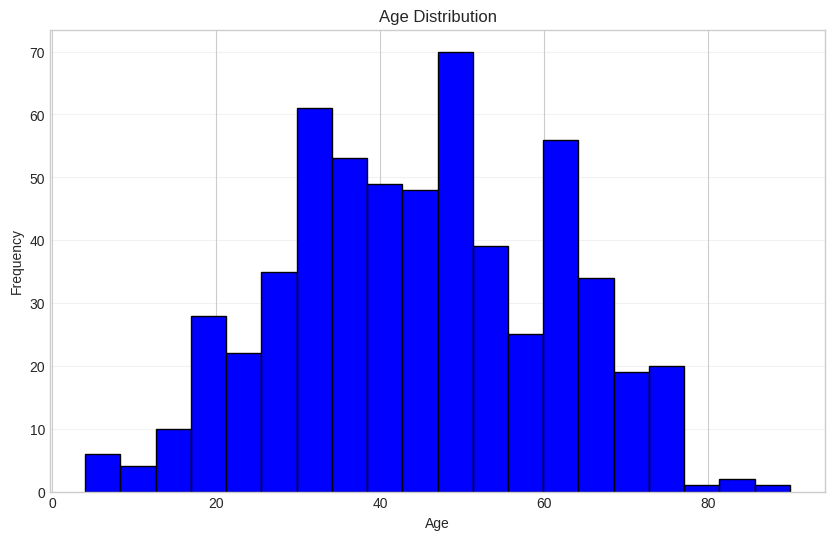

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(dataset['age'], bins=20, color='blue', edgecolor='black')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.25)
plt.show()

Dans ce genre de cas use the log of the column to make it more normal and easier to visualize

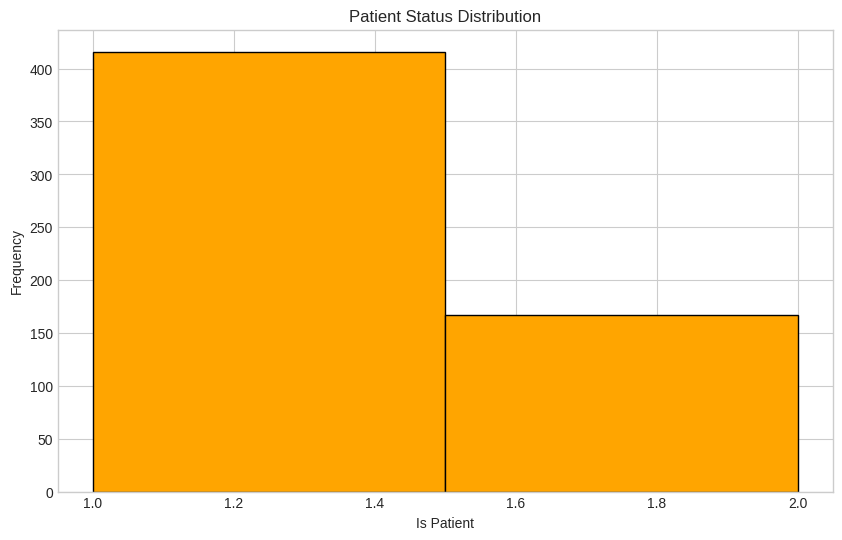

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(dataset['is_patient'], bins=2, color='orange', edgecolor='black')
plt.title('Patient Status Distribution')
plt.xlabel('Is Patient')
plt.ylabel('Frequency')
plt.show()

La nous pouvons voir que dataset est un peu déséquilibré , il y a plus de patients que de non patients 

observons la matrice de corrélation pour voir les relations entre les différentes variables du dataset 
mais avant ca il faut convertir la variable catégorique en numérique pour pouvoir l'utiliser dans la matrice de corrélation

In [11]:
datas = pd.get_dummies(dataset, columns=['gender'])
datas.head()

,age,tot_bilirubin,direct_bilirubin,tot_proteins,albumin,ag_ratio,sgpt,sgot,alkphos,is_patient,gender_Female,gender_Male
0,65,0.7,0.1,187,16,18,6.8,3.3,0.90,1,True,False
1,62,10.9,5.5,699,64,100,7.5,3.2,0.74,1,False,True
2,62,7.3,4.1,490,60,68,7.0,3.3,0.89,1,False,True
3,58,1.0,0.4,182,14,20,6.8,3.4,1.00,1,False,True
4,72,3.9,2.0,195,27,59,7.3,2.4,0.40,1,False,True


after converting the categorical variable to numerical we have seen that we got two new columns one for each category and we know that the correlation between the two columns is -1 because they are mutually exclusive so we can drop one of the two columns because they are redundant and we can keep the other one to represent the gender

In [12]:
datas.drop(columns=['gender_Female'], inplace=True)
datas.head()

,age,tot_bilirubin,direct_bilirubin,tot_proteins,albumin,ag_ratio,sgpt,sgot,alkphos,is_patient,gender_Male
0,65,0.7,0.1,187,16,18,6.8,3.3,0.90,1,False
1,62,10.9,5.5,699,64,100,7.5,3.2,0.74,1,True
2,62,7.3,4.1,490,60,68,7.0,3.3,0.89,1,True
3,58,1.0,0.4,182,14,20,6.8,3.4,1.00,1,True
4,72,3.9,2.0,195,27,59,7.3,2.4,0.40,1,True


Now let's visualize the correlation matrix to see the relationships between the different variables in the dataset and to identify any potential multicollinearity issues that may arise when we build our machine learning model.

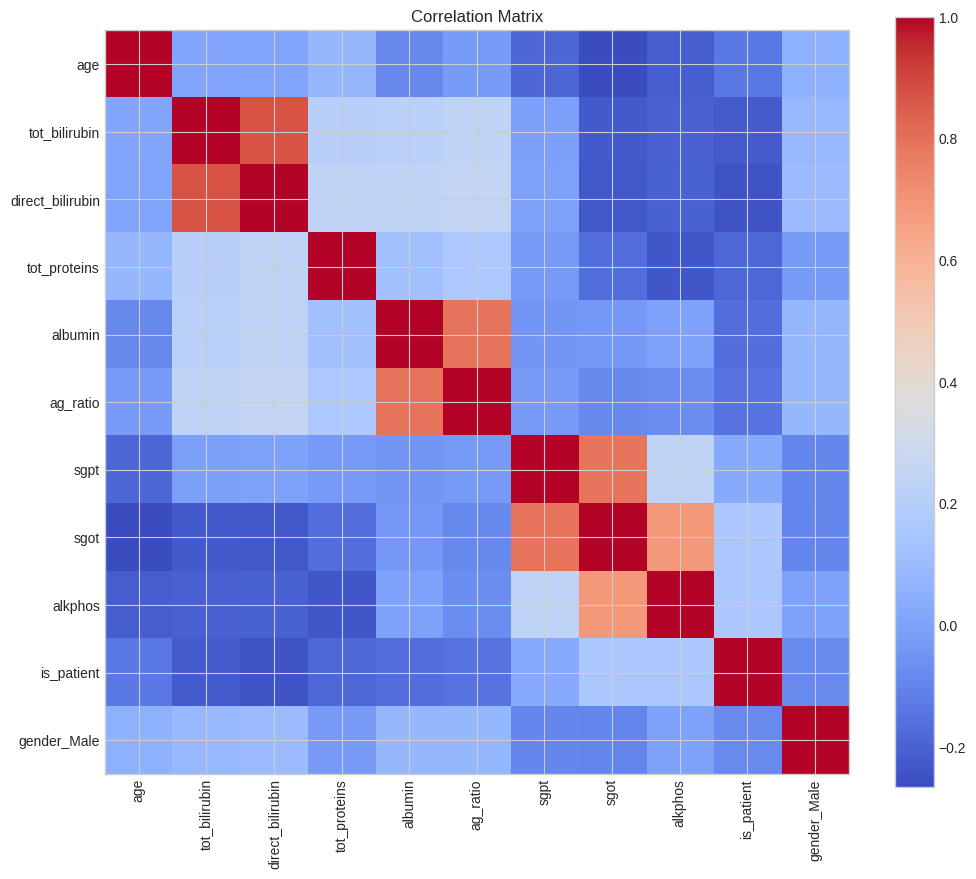

In [ ]:
correlation_matrix = datas.corr()
plt.figure(figsize=(12, 10))
plt.imshow(correlation_matrix, cmap='coolwarm', interpolation='none')
plt.colorbar()
plt.xticks(range(len(correlation_matrix)), correlation_matrix.columns, rotation=90)
plt.yticks(range(len(correlation_matrix)), correlation_matrix.columns)
plt.title('Correlation Matrix')
plt.show()

In [ ]:
print(correlation_matrix)

                       age  tot_bilirubin  direct_bilirubin  tot_proteins  \
age               1.000000       0.011763          0.007529      0.080425   
tot_bilirubin     0.011763       1.000000          0.874618      0.206669   
direct_bilirubin  0.007529       0.874618          1.000000      0.234939   
tot_proteins      0.080425       0.206669          0.234939      1.000000   
albumin          -0.086883       0.214065          0.233894      0.125680   
ag_ratio         -0.019910       0.237831          0.257544      0.167196   
sgpt             -0.187461      -0.008099         -0.000139     -0.028514   
sgot             -0.265924      -0.222250         -0.228531     -0.165453   
alkphos          -0.215968      -0.206015         -0.199850     -0.233784   
is_patient       -0.137351      -0.220208         -0.246046     -0.184866   
gender_Male       0.056560       0.089291          0.100436     -0.027496   

                   albumin  ag_ratio      sgpt      sgot   alkphos  \
age  

Nous observons une forte corrélation entre le tot_bilirubin et le direct_bilirubin ainsi qu'entre sgpt et sgot , albumine et ag_ratio

and we can also see that there is no strong correlation between the target variable and the other variables in the dataset which is good to know in order to choose our moddel 

sachant qu'il n'y a pas de relation lineaire forte entre le target et les autres variables du dataset , on peut essayer d'utiliser un modele de machine learning qui est capable de capturer les relations non linéaires entre les variables pour essayer d'améliorer la performance du modele

Dans ce cas nous allons essayer le random forest pour essayer de capturer les relations non linéaires entre les variables et essayer d'améliorer la performance du modele

In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

X = datas.drop(columns=['is_patient'])
y = datas['is_patient']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.81      0.87      0.84        87
           2       0.52      0.40      0.45        30

    accuracy                           0.75       117
   macro avg       0.67      0.64      0.65       117
weighted avg       0.73      0.75      0.74       117

[[76 11]
 [18 12]]


here we will try to use the random forest with the class weight parameter to try to balance the dataset and see if we can improve the performance of the model

In [ ]:
balanced_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
balanced_model.fit(X_train, y_train)
y_balanced_pred = balanced_model.predict(X_test)
print(classification_report(y_test, y_balanced_pred))
print(confusion_matrix(y_test, y_balanced_pred))

              precision    recall  f1-score   support

           1       0.78      0.85      0.81        87
           2       0.41      0.30      0.35        30

    accuracy                           0.71       117
   macro avg       0.59      0.58      0.58       117
weighted avg       0.68      0.71      0.69       117

[[74 13]
 [21  9]]


nous voyons que les performances du modele sont un peu meilleures que le modele de base mais il y a encore de la place pour l'amélioration , on peut essayer d'utiliser d'autres techniques pour essayer d'améliorer les performances du modele

essayons d'abord par supprimer les variables qui sont fortement corrélées entre elles pour essayer de réduire la multicolinéarité dans le dataset et voir si cela améliore les performances du modele

In [ ]:
datas.drop(columns=['tot_bilirubin', 'sgpt', 'albumin'], inplace=True)
X = datas.drop(columns=['is_patient'])
y = datas['is_patient']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.78      0.87      0.83        87
           2       0.45      0.30      0.36        30

    accuracy                           0.73       117
   macro avg       0.62      0.59      0.59       117
weighted avg       0.70      0.73      0.71       117

[[76 11]
 [21  9]]


nous observons que la multicolinéarité a été réduite mais les performances du modele sont un peu moins bonnes que le modele de base , cela peut être dû au fait que nous avons supprimé des variables qui étaient importantes pour le modele ou que le modele n'est pas capable de capturer les relations non linéaires entre les variables restantes , on peut essayer d'autres techniques pour essayer d'améliorer les performances du modele

essayons de tuner les hyperparamètres du modele pour essayer d'améliorer les performances du modele

In [ ]:

X = datas.drop(columns=['is_patient'])
y = datas['is_patient']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)
model = RandomForestClassifier(n_estimators=500,
max_depth=8,
min_samples_leaf=4,
min_samples_split=8, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.72      0.86      0.78        83
           2       0.37      0.21      0.26        34

    accuracy                           0.67       117
   macro avg       0.55      0.53      0.52       117
weighted avg       0.62      0.67      0.63       117

[[71 12]
 [27  7]]


In [ ]:


from sklearn.model_selection import cross_val_score

X = datas.drop(columns=['is_patient'])
y = datas['is_patient']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)
model = RandomForestClassifier(n_estimators=500,
max_depth=8,
class_weight="balanced",
min_samples_leaf=4,
min_samples_split=8, random_state=42)
train_score = model.fit(X_train, y_train)
cv_scores = cross_val_score(model, X_train, y_train, cv=5)
print("Train:", train_score)
print("CV mean:", cv_scores.mean())
y_pred = model.predict(X_test)
importances = pd.Series(model.feature_importances_, index=X_train.columns)
print(importances.sort_values(ascending=False))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

Train: RandomForestClassifier(class_weight='balanced', max_depth=8, min_samples_leaf=4,
                       min_samples_split=8, n_estimators=500, random_state=42)
CV mean: 0.6888812628689086
tot_proteins        0.159257
albumin             0.142153
direct_bilirubin    0.132120
ag_ratio            0.126643
tot_bilirubin       0.124461
age                 0.110879
sgpt                0.068964
alkphos             0.066835
sgot                0.062123
gender_Male         0.006566
dtype: float64
              precision    recall  f1-score   support

           1       0.80      0.67      0.73        83
           2       0.43      0.59      0.49        34

    accuracy                           0.65       117
   macro avg       0.61      0.63      0.61       117
weighted avg       0.69      0.65      0.66       117

[[56 27]
 [14 20]]


In [7]:
# let's try to change the hyperparameters


from sklearn.model_selection import cross_val_score

X = datas.drop(columns=['is_patient'])
y = datas['is_patient']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)
model = RandomForestClassifier(n_estimators=500,
max_depth=None,
class_weight="balanced",
min_samples_leaf= 2,
min_samples_split=8, random_state=42)
train_score = model.fit(X_train, y_train)
cv_scores = cross_val_score(model, X_train, y_train, cv=5)
print("Train:", train_score)
print("CV mean:", cv_scores.mean())
y_pred = model.predict(X_test)
importances = pd.Series(model.feature_importances_, index=X_train.columns)
print(importances.sort_values(ascending=False))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

Train: RandomForestClassifier(class_weight='balanced', min_samples_leaf=2,
                       min_samples_split=8, n_estimators=500, random_state=42)
CV mean: 0.6846259437199727
tot_proteins        0.156232
albumin             0.138434
ag_ratio            0.127875
age                 0.118288
direct_bilirubin    0.117266
tot_bilirubin       0.110258
alkphos             0.076098
sgpt                0.073010
sgot                0.072653
gender_Male         0.009886
dtype: float64
              precision    recall  f1-score   support

           1       0.77      0.73      0.75        83
           2       0.42      0.47      0.44        34

    accuracy                           0.66       117
   macro avg       0.60      0.60      0.60       117
weighted avg       0.67      0.66      0.66       117

[[61 22]
 [18 16]]


we've gained recall but lost some precision:

Class 1 recall dropped: 0.86 → 0.67
Overall accuracy: 0.67 → 0.65

In [17]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

smote = SMOTE(random_state=42)

rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=4,
    min_samples_split=8,
    random_state=42
)

pipeline = Pipeline([
    ("smote", smote),
    ("model", rf)
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro"
)

print("CV mean:", scores.mean())
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

CV mean: 0.5938295181858584
              precision    recall  f1-score   support

           1       0.86      0.71      0.78        87
           2       0.44      0.67      0.53        30

    accuracy                           0.70       117
   macro avg       0.65      0.69      0.66       117
weighted avg       0.75      0.70      0.72       117

[[62 25]
 [10 20]]


le coeficient de determination (R2) , le rmse  et la matrice de confusion
